In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt

# EJERCICIO 1

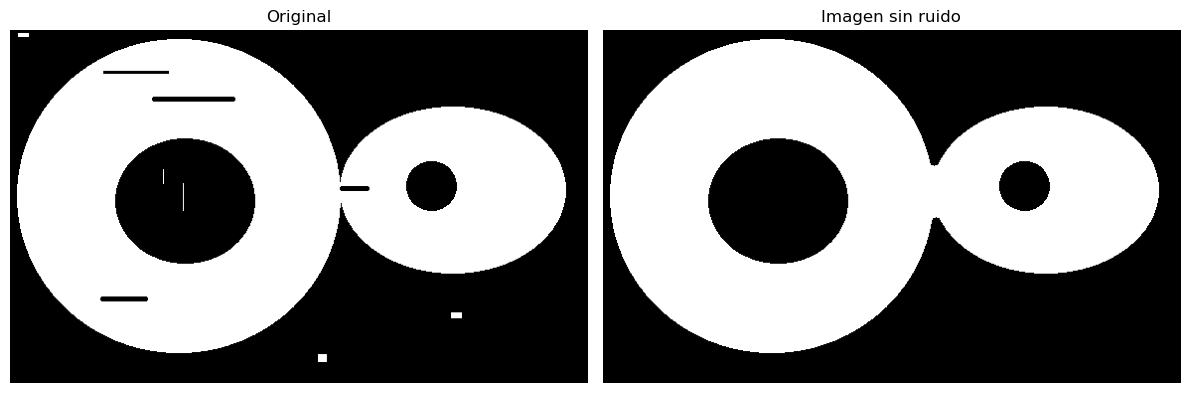

In [6]:
img = cv.imread('circulos2.png', cv.IMREAD_GRAYSCALE)

# Definir el elemento estructural (kernel) para las operaciones morfológicas
kernel = cv.getStructuringElement(cv.MORPH_ELLIPSE, (9, 9))

# ==========================================
# a) Eliminación de ruido blanco
# ==========================================
# Aplicamos apertura (erosión + dilatación) para eliminar los puntos blancos externos
img_sin_ruido_blanco = cv.morphologyEx(img, cv.MORPH_OPEN, kernel)

# ==========================================
# b) Eliminación de ruido negro
# ==========================================
# 1. Obtenemos la imagen negativa
img_negativa = cv.bitwise_not(img_sin_ruido_blanco)

# 2. Aplicamos apertura en la imagen negativa para eliminar el ruido negro
img_negativa_sin_ruido = cv.morphologyEx(img_negativa, cv.MORPH_OPEN, kernel)

# 3. Invertimos de nuevo para regresar a los colores originales
imagen_final = cv.bitwise_not(img_negativa_sin_ruido)



plt.figure(figsize=(12, 6))

# Imagen Original
plt.subplot(1, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')
plt.axis('off')

# Imagen sin ruido final
plt.subplot(1, 2, 2)
plt.imshow(imagen_final, cmap='gray')
plt.title('Imagen sin ruido')
plt.axis('off')

plt.tight_layout()
plt.show()

La Apertura solo elimina ruido blanco:
La operación de apertura sirve para eliminar objetos brillantes pequeños que están sobre un fondo oscuro (es decir, ruido blanco), ya que se come los elementos más pequeños que el kernel. El ruido negro (como las líneas oscuras dentro de las regiones blancas o los puntos negros) no se puede eliminar con una apertura normal, porque para el ordenador el fondo es lo blanco y el ruido es una "ausencia" de información dentro del objeto.

El truco de invertir la imagen (Negativa), los colores se invierten. Lo que antes era el fondo negro pasa a ser blanco.Lo que antes eran los círculos blancos pasan a ser negros. Y el ruido negro que queríamos eliminar ahora se convierte en ruido blanco. Volvemos a aplicar exactamente la misma operación de apertura. Gracias a esto, el algoritmo se deshace de esas manchas (que antes eran ruido negro).


Finalmente, volvemos a invertir la imagen (cv.bitwise_not()) para que los círculos recuperen su color blanco original sobre fondo negro, pero ya completamente libres tanto del ruido blanco como del ruido negro. 

# EJERCICIO 2

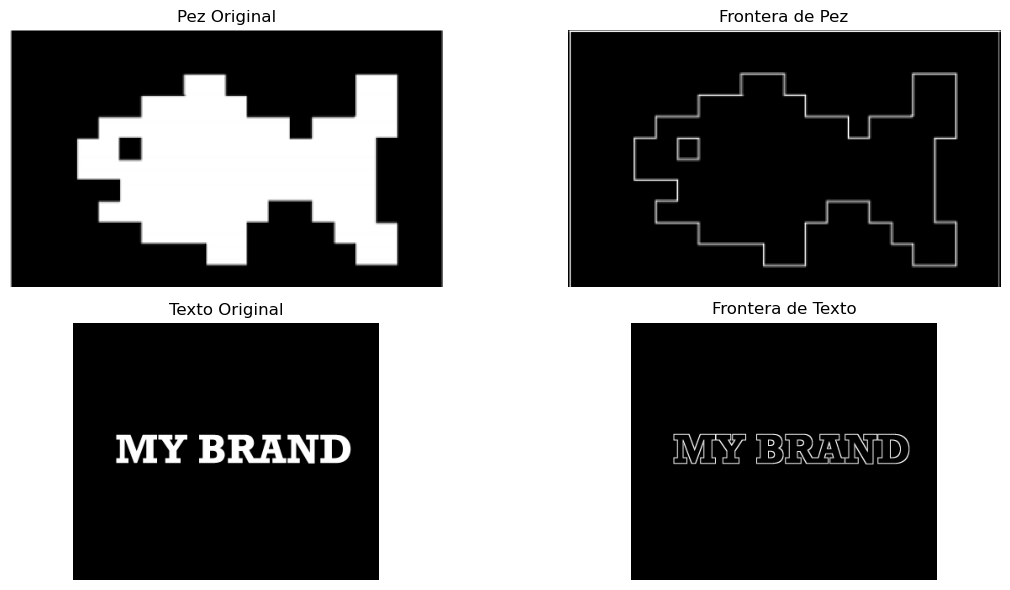

In [8]:
def extraer_fronteras(img):
    """
    Función para extraer las fronteras de una imagen binaria A.
    Se dilata la imagen con un elemento estructural de 3x3 y se extrae el borde.
    """

    kernel = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
    
    # 1. Dilatar la imagen original
    img_dilatada = cv.dilate(img, kernel, iterations=1)
    
    # 2. Obtener la frontera restando la imagen original a la dilatada 
    # (o utilizando cv.subtract para evitar desbordamientos en tipos de datos)
    frontera = cv.subtract(img_dilatada, img)
    
    return frontera

# Cargar las imágenes en escala de grises
pez = cv.imread('pez.png', cv.IMREAD_GRAYSCALE)
texto1 = cv.imread('texto1.png', cv.IMREAD_GRAYSCALE)

# Aplicar la función a ambas imágenes
frontera_pez = extraer_fronteras(pez)
frontera_texto = extraer_fronteras(texto1)



plt.figure(figsize=(12, 6))

# Pez Original
plt.subplot(2, 2, 1)
plt.imshow(pez, cmap='gray')
plt.title('Pez Original')
plt.axis('off')

# Frontera Pez
plt.subplot(2, 2, 2)
plt.imshow(frontera_pez, cmap='gray')
plt.title('Frontera de Pez')
plt.axis('off')

# Texto Original
plt.subplot(2, 2, 3)
plt.imshow(texto1, cmap='gray')
plt.title('Texto Original')
plt.axis('off')

# Frontera Texto
plt.subplot(2, 2, 4)
plt.imshow(frontera_texto, cmap='gray')
plt.title('Frontera de Texto')
plt.axis('off')

plt.tight_layout()
plt.show()

# EJERCICIO 3

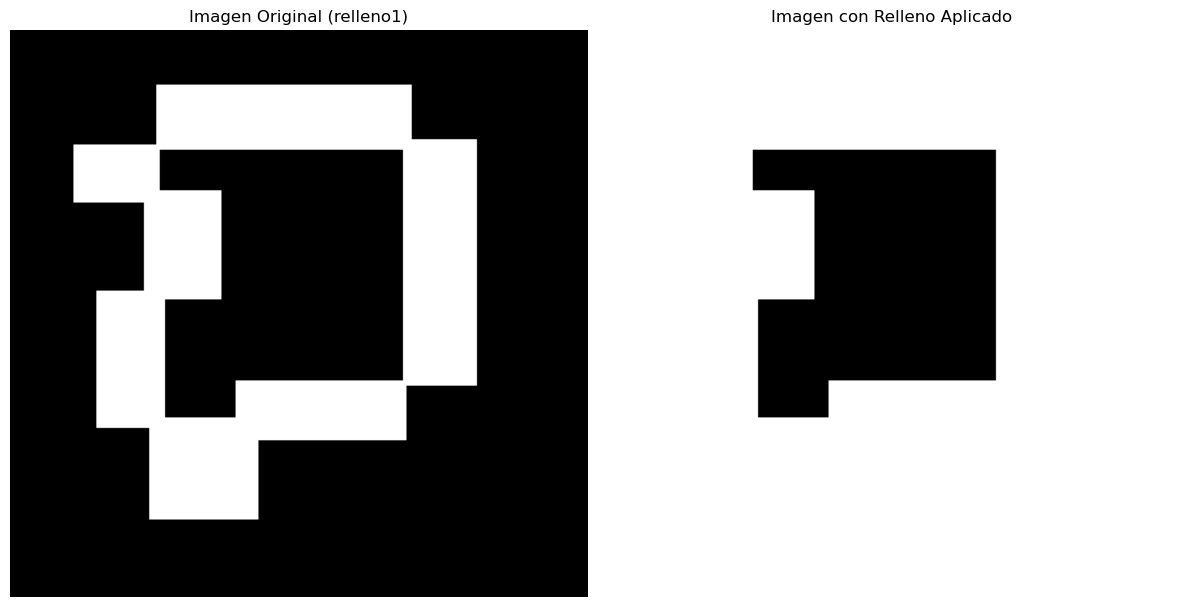

In [9]:
def rellenar_regiones(img, p):
    """
    Función para rellenar regiones (agujeros) en una imagen binaria A.
    img: Imagen binaria original (A) en escala de grises (con valores 0 y 255).
    p: Tupla (x, y) con las coordenadas del punto inicial dentro del hueco.
    """
    # 1. Asegurar formato binario (0 y 255)
    _, img_bin = cv.threshold(img, 127, 255, cv.THRESH_BINARY)
    
    # 2. Obtener el complementario de la imagen (A^c)
    img_inv = cv.bitwise_not(img_bin)
    
    # 3. Inicializar X_0 con un punto de semilla en p (las coordenadas en OpenCV son (x, y))
    X_k = np.zeros_like(img_bin)
    X_k[p[1], p[0]] = 255  # p = (x, y) -> fila es y, columna es x
    
    # 4. Elemento estructural B en forma de cruz de 3x3
    kernel = cv.getStructuringElement(cv.MORPH_CROSS, (3, 3))
    
    # 5. Algoritmo iterativo hasta la convergencia (X_k == X_k_anterior)
    while True:
        X_anterior = X_k.copy()
        
        # Dilatación de X_k-1 con B
        dilatada = cv.dilate(X_k, kernel, iterations=1)
        
        # Intersección con el complementario de A (A^c) -> equivalente a un operador AND lógico
        X_k = cv.bitwise_and(dilatada, img_inv)
        
        # Condición de parada: si la imagen no cambia, terminamos
        if np.array_equal(X_k, X_anterior):
            break
            
    # 6. Combinar la región rellenada con la imagen original (A U X_final)
    imagen_rellena = cv.bitwise_or(img_bin, X_k)
    
    return imagen_rellena, X_k

# Cargar la imagen de relleno
relleno1 = cv.imread('relleno1.png', cv.IMREAD_GRAYSCALE)

# Definir un punto (x, y) de semilla dentro del hueco del objeto.
# Puedes inspeccionar las coordenadas o elegir un punto en el centro del hueco (por ejemplo, x=250, y=250 aprox, 
# o puedes hacer clic/verificar visualmente). Vamos a estimar una coordenada central del agujero:
# Como alternativa interactiva, puedes localizar el punto central. Probemos con una coordenada estimada:
punto_semilla = (250, 220)  # (x, y) -> ajusta según la resolución exacta de tu imagen

# Aplicar la función
try:
    imagen_resultado, mascara_interior = rellenar_regiones(relleno1, punto_semilla)
except Exception as e:
    print(f"Nota: Asegúrate de que el punto semilla esté exactamente dentro del hueco blanco de la figura. Error: {e}")
    imagen_resultado = relleno1

# ==========================================
# Visualización de los resultados
# ==========================================
plt.figure(figsize=(12, 6))

plt.subplot(1, 2, 1)
plt.imshow(relleno1, cmap='gray')
plt.title('Imagen Original (relleno1)')
plt.axis('off')

plt.subplot(1, 2, 2)
plt.imshow(imagen_resultado, cmap='gray')
plt.title('Imagen con Relleno Aplicado')
plt.axis('off')

plt.tight_layout()
plt.show()

# EJERCICIO 4

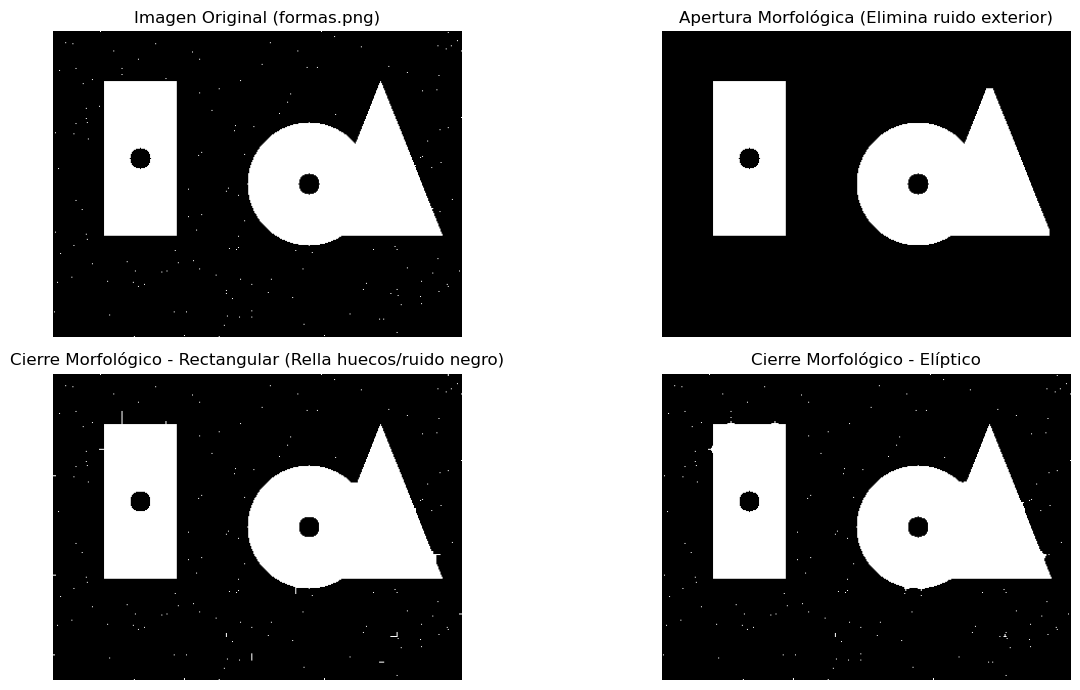

In [16]:

img = cv.imread('formas.png', cv.IMREAD_GRAYSCALE)

# Definir diferentes elementos estructurales (formas y dimensiones)
kernel_pequeno = cv.getStructuringElement(cv.MORPH_RECT, (3, 3))
kernel_mediano = cv.getStructuringElement(cv.MORPH_RECT, (7, 7))
kernel_elipse = cv.getStructuringElement(cv.MORPH_ELLIPSE, (9, 9))

# ==========================================
# 1. Aplicar Apertura Morfológica
# ==========================================
# La apertura elimina el ruido blanco externo (los puntitos brillantes del fondo)
apertura_rect = cv.morphologyEx(img, cv.MORPH_OPEN, kernel_mediano)


# ==========================================
# 2. Aplicar Cierre Morfológico
# ==========================================
# El cierre elimina el ruido negro interno (los puntos negros dentro de las figuras)
cierre_rect = cv.morphologyEx(img, cv.MORPH_CLOSE, kernel_mediano)
cierre_elipse = cv.morphologyEx(img, cv.MORPH_CLOSE, kernel_elipse)

# ==========================================
# 3. Visualización de Resultados con Matplotlib
# ==========================================
plt.figure(figsize=(14, 7))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('Imagen Original (formas.png)')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(apertura_rect, cmap='gray')
plt.title('Apertura Morfológica (Elimina ruido exterior)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(cierre_rect, cmap='gray')
plt.title('Cierre Morfológico - Rectangular (Rella huecos/ruido negro)')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(cierre_elipse, cmap='gray')
plt.title('Cierre Morfológico - Elíptico')
plt.axis('off')

plt.tight_layout()
plt.show()


1. Apertura Morfológica (Erosión seguida de Dilatación): Como se aprecia en el segundo recuadro de la imagen, elimina por completo todo el ruido blanco exterior (los pequeños puntos brillantes dispersos por el fondo negro), dejando el fondo completamente limpio y respetando la geometría de las figuras principales. Es la operación óptima cuando necesitas limpiar fondos ruidosos (motas de ruido claro), desconectar objetos que están levemente unidos por un puente fino de píxeles, o suavizar contornos externos sin alterar el tamaño global de los objetos de interés.
   


3. Cierre Morfológico (Dilatación seguida de Erosión): Al estar enfocado en expandir las zonas blancas para "puentear" espacios, no elimina el ruido blanco del fondo (por eso los puntitos del fondo siguen apareciendo). Su propósito principal es rellenar huecos y grietas internas. Sin embargo, como los agujeros negros dentro de las figuras son más grandes que el tamaño del elemento estructural usado, estos persisten a menos que se use un kernel excesivamente grande (lo cual terminaría deformando los bordes de los objetos). Es muy útil cuando necesitas reparar objetos fragmentados, rellenar agujeros o huecos negros internos dentro de las regiones de interés, o cerrar pequeñas fisuras en los bordes de una silueta.

Conclusión

Ambas operaciones son complementarias:
Usa la apertura cuando el problema principal sea el ruido externo en el fondo.
Usa el cierre cuando el problema sean las ausencias de información o huecos en el interior de los objetos. En muchos casos reales de procesamiento de imágenes, se aplica una secuencia de ambas (primero apertura para limpiar el fondo y luego cierre si se requiere corregir algún interior).